In [ ]:
!wget -q https://hl2data.z5.web.core.windows.net/holoassist-data-release/data-annotation-trainval-v1_1.json
!ls -lh data-annotation-trainval-v1_1.json

-rw-r--r-- 1 root root 112M Jun 14  2024 data-annotation-trainval-v1_1.json


In [ ]:
import json

with open("data-annotation-trainval-v1_1.json") as f:
    data = json.load(f)

print("Type:", type(data))
print("Number of items:", len(data))

Type: <class 'list'>
Number of items: 1758


In [ ]:
first_item = data[0]

print("Type of one item:", type(first_item))

if isinstance(first_item, dict):
    print("Keys inside:", list(first_item.keys()))

Type of one item: <class 'dict'>
Keys inside: ['batch', 'videoMetadata', 'events', 'taskId', 'taskType', 'video_name']


In [ ]:
item = data[0]

print("video_name:", item["video_name"])
print("taskType:", item["taskType"])
print("taskId:", item["taskId"])
print("batch:", item["batch"])
print("videoMetadata:", str(item["videoMetadata"])[:500])

video_name: R0027-12-GoPro
taskType: setup gopro
taskId: 63dadf3f4cc12c20152c3aab
batch: 202301_2221_10fps
videoMetadata: {'audio': {'codec': 'aac', 'bitrate': '70', 'sample_rate': 48000, 'stream': 0, 'channels': {'raw': 'mono', 'value': 1}}, 'video': {'container': 'mov', 'bitrate': 2257, 'stream': 0, 'codec': 'h264', 'resolution': {'w': 896, 'h': 504}, 'resolutionSquare': {'w': 896, 'h': 504}, 'aspect': {'x': 16, 'y': 9, 'string': '16:9', 'value': 1.7777777777777777}, 'rotate': 0, 'fps': 24.46, 'pixelString': '1:1', 'pixel': 1}, 'duration': {'raw': '00:06:46.21', 'seconds': 406}}


In [ ]:
events = item["events"]

print("Type of events:", type(events))
print("Number of events:", len(events))
print("First event:")
print(json.dumps(events[0], indent=2)[:1500])

Type of events: <class 'list'>
Number of events: 185
First event:
{
  "id": 1,
  "label": "Narration",
  "start": 0.002,
  "type": "range",
  "attributes": {
    "Long form description": "The student grabs the GoPro from the packaging and holds it in his hands with a little difficulty, grabs the camera and opens it, and just touches the battery, holds the GoPro in his hands for a few minutes, then removes the battery and the SD card, placing them on the table, inserts the battery and turns on the GoPro, and turns it off, take the lock screw and inserts it, removes it, places the stick, puts the lock screw, removes it and finally places it on the table."
  },
  "end": 406.135
}


In [ ]:
from collections import Counter

task_counts = Counter(item["taskType"] for item in data)

for task, n in task_counts.most_common():
    print(n, task)

143 setup switch
135 setup camera
134 setup gopro
124 disassemble tray table
120 disassemble stool
115 disassemble nightstand
112 assemble tray table
109 setup big printer
108 assemble nightstand
101 assemble stool
100 make coffee with nespresso machine
94 setup small printer
85 disassemble utility cart
74 assemble computer
68 assemble utility cart
44 make coffee with espresso machine
25 change circuit breaker
24 assemble laser scanner
24 fix motorcycle
19 change belt


In [ ]:
label_counts = Counter()

for item in data:
    for ev in item["events"]:
        label_counts[ev["label"]] += 1

print(label_counts)

Counter({'Fine grained action': 149253, 'Conversation': 32392, 'Coarse grained action': 12542, 'Narration': 1758})


In [ ]:
for item in data[:5]:
    n_coarse = 0
    for ev in item["events"]:
        if ev["label"] == "Coarse grained action":
            n_coarse += 1
    print(item["video_name"], "|", item["taskType"], "|",
          item["videoMetadata"]["duration"]["seconds"], "seconds |",
          n_coarse, "big steps")

R0027-12-GoPro | setup gopro | 406 seconds | 9 big steps
R005-7July-GoPro | setup gopro | 295 seconds | 11 big steps
R007-7July-DSLR | setup camera | 111 seconds | 8 big steps
R012-7July-Nespresso | make coffee with nespresso machine | 122 seconds | 5 big steps
R014-7July-DSLR | setup camera | 354 seconds | 8 big steps


In [ ]:
for ev in data[0]["events"]:
    if ev["label"] == "Fine grained action":
        print(json.dumps(ev, indent=2))
        break

{
  "id": 119,
  "label": "Fine grained action",
  "start": 11.01,
  "type": "range",
  "attributes": {
    "Action Correctness": "Correct Action",
    "Incorrect Action Explanation": "none",
    "Incorrect Action Corrected by": "none",
    "Verb": "approach",
    "Adjective": "none",
    "Noun": "gopro",
    "adverbial": "none"
  },
  "end": 12.21
}


In [ ]:
correctness_counts = Counter()

for item in data:
    for ev in item["events"]:
        if ev["label"] == "Fine grained action":
            value = ev["attributes"].get("Action Correctness", "missing")
            correctness_counts[value] += 1

print(correctness_counts)

Counter({'Correct Action': 141691, 'Wrong Action, corrected by instructor verbally': 4052, 'Wrong Action, corrected by student': 3061, 'otherwise': 357, 'Wrong Action, not corrected': 92})


In [ ]:
for item in data[:5]:
    n_wrong = 0
    for ev in item["events"]:
        if ev["label"] == "Fine grained action":
            if ev["attributes"].get("Action Correctness") != "Correct Action":
                n_wrong += 1
    print(item["video_name"], "->", n_wrong, "actions that are not 'Correct Action'")

R0027-12-GoPro -> 6 actions that are not 'Correct Action'
R005-7July-GoPro -> 3 actions that are not 'Correct Action'
R007-7July-DSLR -> 1 actions that are not 'Correct Action'
R012-7July-Nespresso -> 0 actions that are not 'Correct Action'
R014-7July-DSLR -> 14 actions that are not 'Correct Action'


In [ ]:
video_to_check = "R014-7July-DSLR"

for item in data:
    if item["video_name"] == video_to_check:
        chosen = item
        break

print("Video:", chosen["video_name"], "| task:", chosen["taskType"])
print()

for ev in chosen["events"]:
    if ev["label"] == "Fine grained action":
        attrs = ev["attributes"]
        if attrs.get("Action Correctness") != "Correct Action":
            print("From", ev["start"], "to", ev["end"], "seconds")
            print("  Action:", attrs.get("Verb"), attrs.get("Noun"))
            print("  Status:", attrs.get("Action Correctness"))
            print("  Why wrong:", attrs.get("Incorrect Action Explanation"))
            print("  Corrected by:", attrs.get("Incorrect Action Corrected by"))
            print()

Video: R014-7July-DSLR | task: setup camera

From 12.914 to 16.214 seconds
  Action: rotate lens_cover
  Status: Wrong Action, corrected by instructor verbally
  Why wrong: The student twists the lens cover instead of the lens.
  Corrected by: 12

From 17.2 to 19.212 seconds
  Action: rotate lens_cover
  Status: Wrong Action, corrected by instructor verbally
  Why wrong: The student twists the lens cover instead the lens.
  Corrected by: 12

From 19.307 to 21.9 seconds
  Action: withdraw lens_cover
  Status: Wrong Action, corrected by instructor verbally
  Why wrong: The student detaches the lens cover instead the lens.
  Corrected by: 12

From 50.45 to 53.956 seconds
  Action: rotate lens
  Status: Wrong Action, corrected by instructor verbally
  Why wrong: The student should rotate the entire body.
  Corrected by: 24

From 62.345 to 83.8 seconds
  Action: rotate dslr
  Status: otherwise
  Why wrong: The student rotates it incorrectly.
  Corrected by: none

From 91.1 to 93.336 seconds

In [ ]:
for ev in chosen["events"]:
    if ev["id"] == 12:
        print(json.dumps(ev, indent=2))

{
  "id": 12,
  "label": "Conversation",
  "start": 14.795,
  "type": "range",
  "attributes": {
    "Conversation Purpose": "instructor-start-conversation_correct the wrong action",
    "sequence": "11,13,14",
    "Transcription": "The lens is the eh, like the big, the entire thing in the front.",
    "Transcription Confidence": "none"
  },
  "end": 19.488
}


In [ ]:
for ev in chosen["events"]:
    if ev["label"] == "Conversation" and ev["start"] < 40:
        attrs = ev["attributes"]
        print(ev["id"], "|", ev["start"], "-", ev["end"], "|",
              attrs.get("Conversation Purpose"), "|", attrs.get("Transcription"))

137 | 2.1 - 2.4 | instructor-start-conversation_confirming the previous action | Okay
2 | 2.457 - 5.157 | instructor-start-conversation_describing high-level instruction | you want to pick up the camera.
7 | 9.2 - 11.042 | instructor-start-conversation_describing high-level instruction | Now detach the lens.
12 | 14.795 - 19.488 | instructor-start-conversation_correct the wrong action | The lens is the eh, like the big, the entire thing in the front.
15 | 22.444 - 25.509 | instructor-reply-to-student_follow-up instruction | So keep look on the opposite side.
17 | 28.116 - 39.3 | instructor-reply-to-student_follow-up instruction | Um, next, next to the eh, the lens, it's on the front side of the camera, there should be a button close to your left hand.


In [ ]:
VIDEO_URL = "https://hl2data.z5.web.core.windows.net/holoassist-data-release/video_compress.tar"

!mkdir -p clips
!cd clips && curl -sL "{VIDEO_URL}" | head -c 3G | tar -xf -

tar: Unexpected EOF in archive
tar: Unexpected EOF in archive
tar: Error is not recoverable: exiting now


In [ ]:
!du -sh clips
!find clips -name "*.mp4"

3.1G	clips


In [ ]:
!ls clips | head -20
!echo "-----"
!find clips -type f | head -20
!echo "-----"
!find clips -type f | wc -l

R0027-12-GoPro
R004-7July-GoPro
R005-7July-GoPro
R006-7July-Switch
R007-7July-DSLR
R012-7July-Nespresso
R013-7July-Nespresso
R014-7July-DSLR
R015-7July-Switch
R026-11July-Navvis
R029-12July-DSLR
R030-12July-Nespresso
R031-12July-SmallPrinter
R032-12July-BigPrinter
R033-12July-GoPro
R034-12July-Switch
R035-12July-Nespresso
R036-12July-DSLR
R037-13July-GoPro
R039-13July-DSLR
-----
clips/z050-june-27-22-gopro/Export_py/Video/VideoMp4Timing.txt
clips/z050-june-27-22-gopro/Export_py/Video/Pose_sync.txt
clips/z022-june-21-22-gopro/Export_py/Video/VideoMp4Timing.txt
clips/z022-june-21-22-gopro/Export_py/Video/Pose_sync.txt
clips/z088-july-07-22-rashult_disassemble/Export_py/Video/VideoMp4Timing.txt
clips/z088-july-07-22-rashult_disassemble/Export_py/Video/Pose_sync.txt
clips/z088-july-07-22-gladom_disassemble/Export_py/Video/VideoMp4Timing.txt
clips/z088-july-07-22-gladom_disassemble/Export_py/Video/Pose_sync.txt
clips/z076-july-01-22-marius_disassemble/Export_py/Video/VideoMp4Timing.txt
clip

In [ ]:
from pathlib import Path
from collections import Counter

files = [p for p in Path("clips").rglob("*") if p.is_file()]
print("Total files:", len(files))
print("File types:", Counter(p.suffix for p in files))

print()
for p in Path("clips/R014-7July-DSLR").rglob("*"):
    if p.is_file():
        print(p, round(p.stat().st_size / 1e6, 1), "MB")

Total files: 2789
File types: Counter({'.txt': 2789})

clips/R014-7July-DSLR/Export_py/Video/VideoMp4Timing.txt 0.0 MB
clips/R014-7July-DSLR/Export_py/Video/Pose_sync.txt 3.0 MB


In [ ]:
!curl -sL "{VIDEO_URL}" | head -c 10G | tar -tv | grep -m 5 "\.mp4"

-rw-r--r-- REDMOND.wanxin/REDMOND.domain users 93620115 2023-10-04 23:30 R0027-12-GoPro/Export_py/Video_compress.mp4
-rw-r--r-- REDMOND.wanxin/REDMOND.domain users 113159472 2023-10-04 22:50 R004-7July-GoPro/Export_py/Video_compress.mp4
-rw-r--r-- REDMOND.wanxin/REDMOND.domain users  88487150 2023-10-04 22:42 R005-7July-GoPro/Export_py/Video_compress.mp4
-rw-r--r-- REDMOND.wanxin/REDMOND.domain users  48273821 2023-10-04 22:21 R006-7July-Switch/Export_py/Video_compress.mp4
-rw-r--r-- REDMOND.wanxin/REDMOND.domain users  31053824 2023-10-04 22:49 R007-7July-DSLR/Export_py/Video_compress.mp4


In [ ]:
VIDEO_URL = "https://hl2data.z5.web.core.windows.net/holoassist-data-release/video_compress.tar"

!rm -rf clips
!mkdir -p clips

!cd clips && curl -sL "{VIDEO_URL}" | head -c 12G | tar -xf - --occurrence=1 R007-7July-DSLR/Export_py/Video_compress.mp4 R012-7July-Nespresso/Export_py/Video_compress.mp4 R014-7July-DSLR/Export_py/Video_compress.mp4

!find clips -name "*.mp4" | xargs ls -lh

-rw-r--r-- 1 549287358 500000513 30M Oct  4  2023 clips/R007-7July-DSLR/Export_py/Video_compress.mp4
-rw-r--r-- 1 549287358 500000513 26M Oct  4  2023 clips/R012-7July-Nespresso/Export_py/Video_compress.mp4
-rw-r--r-- 1 549287358 500000513 91M Oct  4  2023 clips/R014-7July-DSLR/Export_py/Video_compress.mp4


In [ ]:
import cv2
import matplotlib.pyplot as plt

video_path = "clips/R014-7July-DSLR/Export_py/Video_compress.mp4"
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
n_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)
width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)

print("frames per second:", fps)
print("total frames:", n_frames)
print("duration (s):", n_frames / fps)
print("size:", width, "x", height)

frames per second: 29.957
total frames: 10618.0
duration (s): 354.44136595787296
size: 454.0 x 256.0


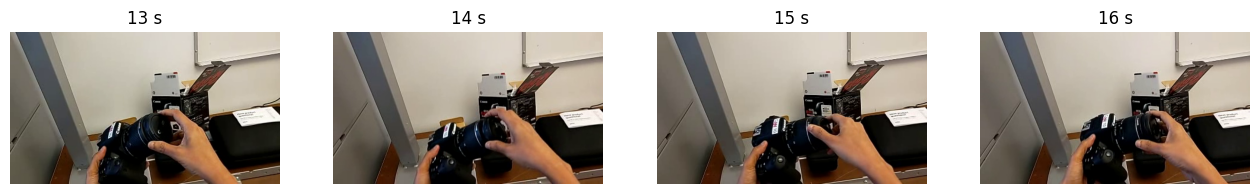

In [ ]:
times = [13, 14, 15, 16]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, t in zip(axes, times):
    cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
    ok, frame = cap.read()
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(str(t) + " s")
    ax.axis("off")

plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!mkdir -p /content/drive/MyDrive/egocollab
!cp data-annotation-trainval-v1_1.json /content/drive/MyDrive/egocollab/
!cp -r clips /content/drive/MyDrive/egocollab/
!ls -R /content/drive/MyDrive/egocollab

/content/drive/MyDrive/egocollab:
clips  data-annotation-trainval-v1_1.json

/content/drive/MyDrive/egocollab/clips:
R007-7July-DSLR  R012-7July-Nespresso  R014-7July-DSLR

/content/drive/MyDrive/egocollab/clips/R007-7July-DSLR:
Export_py

/content/drive/MyDrive/egocollab/clips/R007-7July-DSLR/Export_py:
Video_compress.mp4

/content/drive/MyDrive/egocollab/clips/R012-7July-Nespresso:
Export_py

/content/drive/MyDrive/egocollab/clips/R012-7July-Nespresso/Export_py:
Video_compress.mp4

/content/drive/MyDrive/egocollab/clips/R014-7July-DSLR:
Export_py

/content/drive/MyDrive/egocollab/clips/R014-7July-DSLR/Export_py:
Video_compress.mp4


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/egocollab"

def get_frames(video_name, start, end, n_frames=4):
    path = f"{BASE}/clips/{video_name}/Export_py/Video_compress.mp4"
    cap = cv2.VideoCapture(path)
    wanted_times = np.linspace(start, end, n_frames)

    frames = []
    used_times = []
    for t in wanted_times:
        cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
        ok, frame = cap.read()
        if ok:
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            used_times.append(t)

    cap.release()
    return frames, used_times


def show_frames(frames, times):
    fig, axes = plt.subplots(1, len(frames), figsize=(4 * len(frames), 3))
    if len(frames) == 1:
        axes = [axes]
    for ax, img, t in zip(axes, frames, times):
        ax.imshow(img)
        ax.set_title(f"{t:.1f} s")
        ax.axis("off")
    plt.show()

Got 6 frames


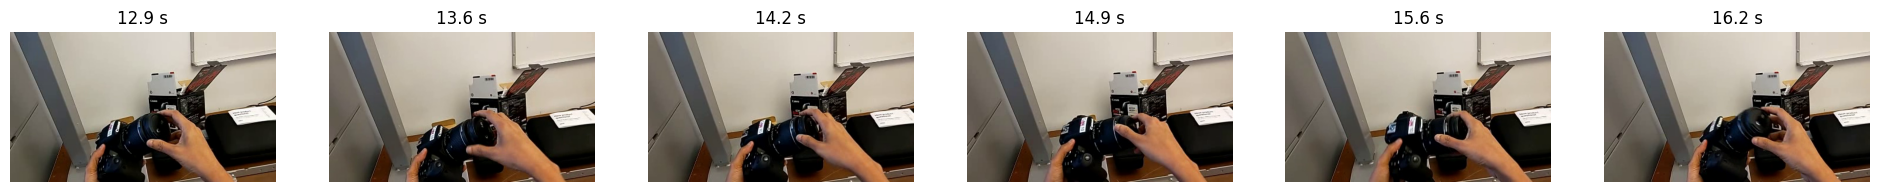

In [ ]:
frames, times = get_frames("R014-7July-DSLR", 12.914, 16.214, n_frames=6)

print("Got", len(frames), "frames")
show_frames(frames, times)

Got 12 frames


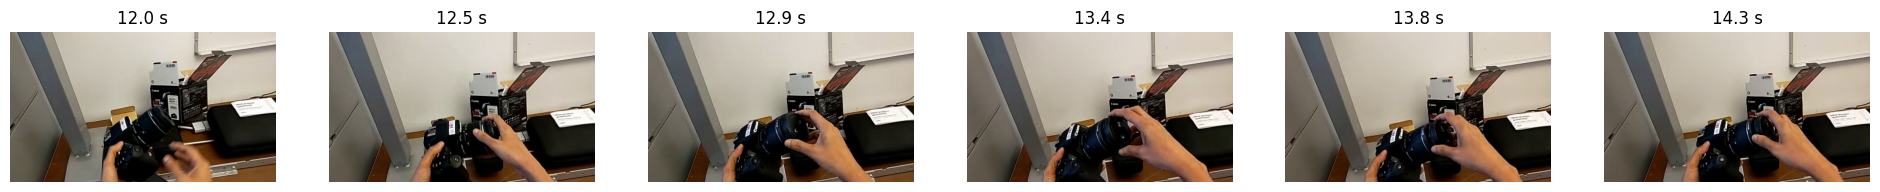

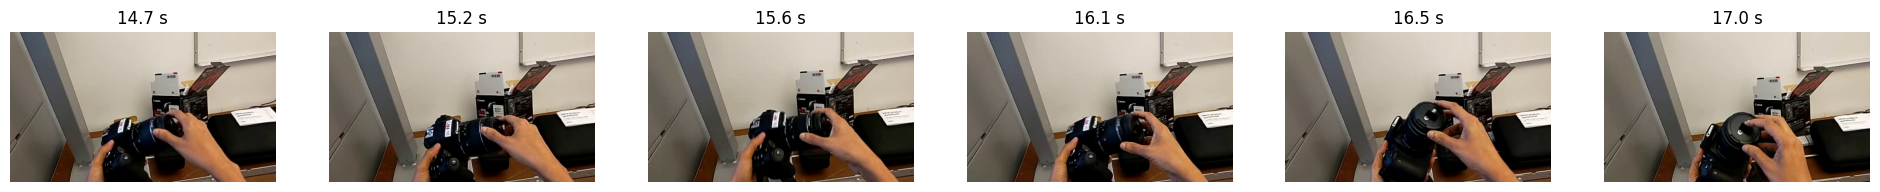

In [ ]:
frames, times = get_frames("R014-7July-DSLR", 12.0, 17.0, n_frames=12)

print("Got", len(frames), "frames")
show_frames(frames[:6], times[:6])
show_frames(frames[6:], times[6:])

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/egocollab"

with open(f"{BASE}/data-annotation-trainval-v1_1.json") as f:
    data = json.load(f)
print("Videos in annotation file:", len(data))


def get_frames(video_name, start, end, n_frames=4):
    path = f"{BASE}/clips/{video_name}/Export_py/Video_compress.mp4"
    cap = cv2.VideoCapture(path)
    wanted_times = np.linspace(start, end, n_frames)

    frames = []
    used_times = []
    for t in wanted_times:
        cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
        ok, frame = cap.read()
        if ok:
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            used_times.append(t)

    cap.release()
    return frames, used_times


def show_frames(frames, times):
    fig, axes = plt.subplots(1, len(frames), figsize=(4 * len(frames), 3))
    if len(frames) == 1:
        axes = [axes]
    for ax, img, t in zip(axes, frames, times):
        ax.imshow(img)
        ax.set_title(f"{t:.1f} s")
        ax.axis("off")
    plt.show()


frames, times = get_frames("R014-7July-DSLR", 12.914, 16.214, n_frames=6)
print("Test: got", len(frames), "frames")

Mounted at /content/drive
Videos in annotation file: 1758
Test: got 6 frames


In [ ]:
import torch
from transformers import AutoProcessor, LlavaOnevisionForConditionalGeneration

MODEL_ID = "llava-hf/llava-onevision-qwen2-0.5b-ov-hf"

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print("Using device:", device)

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = LlavaOnevisionForConditionalGeneration.from_pretrained(
    MODEL_ID, torch_dtype=dtype
).to(device)
model.eval()
print("Model loaded.")

Using device: cuda


processor_config.json:   0%|          | 0.00/178 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/1.73k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.59k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.79GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/716 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/126 [00:00<?, ?B/s]

Model loaded.


In [ ]:
from PIL import Image

frames, times = get_frames("R014-7July-DSLR", 12.914, 16.214, n_frames=4)
images = [Image.fromarray(f) for f in frames]

question = "Describe what the person is doing in these frames."

conversation = [
    {
        "role": "user",
        "content": [{"type": "image"} for _ in images]
                   + [{"type": "text", "text": question}],
    }
]

prompt = processor.apply_chat_template(conversation, add_generation_prompt=True)
inputs = processor(images=images, text=prompt, return_tensors="pt").to(device, dtype)

with torch.no_grad():
    output_ids = model.generate(**inputs, max_new_tokens=100, do_sample=False)

answer = processor.decode(
    output_ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True
)
print(answer)

The person is holding a camera lens, possibly preparing to use it or inspecting it.


In [ ]:
from PIL import Image

def ask_model(images, question, max_new_tokens=100):
    conversation = [
        {
            "role": "user",
            "content": [{"type": "image"} for _ in images]
                       + [{"type": "text", "text": question}],
        }
    ]
    prompt = processor.apply_chat_template(conversation, add_generation_prompt=True)
    inputs = processor(images=images, text=prompt, return_tensors="pt").to(device, dtype)
    with torch.no_grad():
        output_ids = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return processor.decode(
        output_ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True
    )


video_name = "R014-7July-DSLR"
task = next(item["taskType"] for item in data if item["video_name"] == video_name)
print("Task from annotations:", task)

frames, times = get_frames(video_name, 12.914, 16.214, n_frames=4)
images = [Image.fromarray(f) for f in frames]

base_question = "Describe what the person is doing in these frames."
question_A = base_question
question_B = f"The person is performing this task: {task}. " + base_question

answer_A = ask_model(images, question_A)
answer_B = ask_model(images, question_B)

print()
print("A (generic):", answer_A)
print()
print("B (with task):", answer_B)

Task from annotations: setup camera

A (generic): The person is holding a camera lens, possibly preparing to use it or inspecting it.

B (with task): The person is holding a camera lens and appears to be setting it up or adjusting it. They are using their hands to manipulate the lens, possibly to ensure it is properly aligned or to fine-tune its focus or aperture settings. The setting suggests that they are either preparing to use the camera or have just finished using it.


In [ ]:
mistake_question = (
    "Is the person making a mistake while doing this task? "
    "Answer yes or no first, then explain in one sentence and say what they should do instead."
)

def run_case(video_name, start, end, n_frames=4):
    task = next(item["taskType"] for item in data if item["video_name"] == video_name)
    frames, times = get_frames(video_name, start, end, n_frames=n_frames)
    images = [Image.fromarray(f) for f in frames]

    question_A = mistake_question
    question_B = f"The person is performing this task: {task}. " + mistake_question

    print("Video:", video_name, "| window:", round(start, 1), "-", round(end, 1), "s")
    print("A (generic):", ask_model(images, question_A))
    print("B (with task):", ask_model(images, question_B))
    print()


# Case 1: labeled mistake (twisting the lens cover)
run_case("R014-7July-DSLR", 12.914, 16.214)

# Case 2: find a correct action in the Nespresso video
video2 = "R012-7July-Nespresso"
item2 = next(item for item in data if item["video_name"] == video2)

for ev in item2["events"]:
    if ev["label"] == "Fine grained action":
        attrs = ev["attributes"]
        if attrs.get("Action Correctness") == "Correct Action" and ev["end"] - ev["start"] >= 2:
            print("Correct action in labels:", attrs.get("Verb"), attrs.get("Noun"))
            run_case(video2, ev["start"], ev["end"])
            break

Video: R014-7July-DSLR | window: 12.9 - 16.2 s
A (generic): No, the person is making a mistake. The person is holding the camera lens up to the box, but the box is open and the lens is not being properly attached to the camera. The person should close the box before attaching the lens to the camera.
B (with task): No, the person is not making a mistake while setting up the camera. They are following the correct steps to properly position and adjust the camera.

Correct action in labels: place cup
Video: R012-7July-Nespresso | window: 20.0 - 22.2 s
A (generic): No, the person is making a mistake. The person is pouring coffee into the cup, but the coffee is not being poured into the cup. The person should pour the coffee into the cup using the coffee maker.
B (with task): No, the person is not making a mistake while doing this task. The person is using the Nespresso machine to make coffee, and the machine is functioning correctly.



In [ ]:
strict_question = (
    "Is the person doing this step right or wrong? "
    "Reply with exactly one word: RIGHT or WRONG."
)

def parse_verdict(text):
    t = text.upper()
    if "WRONG" in t and "RIGHT" not in t:
        return "wrong"
    if "RIGHT" in t and "WRONG" not in t:
        return "right"
    return "unclear"

def run_case_strict(video_name, start, end, truth, n_frames=4):
    task = next(item["taskType"] for item in data if item["video_name"] == video_name)
    frames, times = get_frames(video_name, start, end, n_frames=n_frames)
    images = [Image.fromarray(f) for f in frames]

    q_A = strict_question
    q_B = f"The person is performing this task: {task}. " + strict_question

    for name, q in [("A (generic)", q_A), ("B (with task)", q_B)]:
        raw = ask_model(images, q, max_new_tokens=5)
        print(f"{video_name} {start:.1f}-{end:.1f}s | truth: {truth} | {name}: raw='{raw}' -> {parse_verdict(raw)}")

run_case_strict("R014-7July-DSLR", 12.914, 16.214, truth="wrong")
run_case_strict("R012-7July-Nespresso", 20.0, 22.2, truth="right")

R014-7July-DSLR 12.9-16.2s | truth: wrong | A (generic): raw='RIGHT' -> right
R014-7July-DSLR 12.9-16.2s | truth: wrong | B (with task): raw='RIGHT' -> right
R012-7July-Nespresso 20.0-22.2s | truth: right | A (generic): raw='RIGHT' -> right
R012-7July-Nespresso 20.0-22.2s | truth: right | B (with task): raw='RIGHT' -> right


In [ ]:
import random
import pandas as pd

random.seed(0)

WRONG_TYPES = [
    "Wrong Action, corrected by instructor verbally",
    "Wrong Action, corrected by student",
    "Wrong Action, not corrected",
]
videos = ["R014-7July-DSLR", "R007-7July-DSLR", "R012-7July-Nespresso"]

wrong_cases = []
right_pool = []

for vname in videos:
    item = next(it for it in data if it["video_name"] == vname)
    task = item["taskType"]

    fine = [ev for ev in item["events"] if ev["label"] == "Fine grained action"]
    wrong_windows = [
        (ev["start"], ev["end"]) for ev in fine
        if ev["attributes"].get("Action Correctness") in WRONG_TYPES
    ]

    for ev in fine:
        attrs = ev["attributes"]
        start, end = ev["start"], ev["end"]
        if end - start < 1.5:
            continue

        row = {
            "video": vname, "task": task, "start": start, "end": end,
            "action": f'{attrs.get("Verb")} {attrs.get("Noun")}',
            "why_wrong": attrs.get("Incorrect Action Explanation"),
        }
        correctness = attrs.get("Correctness") or attrs.get("Action Correctness")

        if correctness in WRONG_TYPES:
            row["truth"] = "wrong"
            wrong_cases.append(row)
        elif correctness == "Correct Action":
            overlaps = any(start < we and end > ws for ws, we in wrong_windows)
            if not overlaps:
                row["truth"] = "right"
                right_pool.append(row)

right_cases = random.sample(right_pool, min(len(wrong_cases), len(right_pool)))

test_set = pd.DataFrame(wrong_cases + right_cases)
test_set.to_csv(f"{BASE}/test_set.csv", index=False)

print("Mistake windows:", len(wrong_cases))
print("Correct windows:", len(right_cases))
print(test_set[["video", "start", "end", "action", "truth"]].head(10))

Mistake windows: 11
Correct windows: 11
             video    start      end               action  truth
0  R014-7July-DSLR   12.914   16.214    rotate lens_cover  wrong
1  R014-7July-DSLR   17.200   19.212    rotate lens_cover  wrong
2  R014-7July-DSLR   19.307   21.900  withdraw lens_cover  wrong
3  R014-7July-DSLR   50.450   53.956          rotate lens  wrong
4  R014-7July-DSLR   91.100   93.336            drop lens  wrong
5  R014-7July-DSLR  168.247  171.252         press button  wrong
6  R014-7July-DSLR  206.916  213.957    open battery_door  wrong
7  R014-7July-DSLR  214.200  219.400    open battery_door  wrong
8  R014-7July-DSLR  225.592  227.647          rotate dslr  wrong
9  R014-7July-DSLR  228.200  230.800         pull battery  wrong


In [ ]:
test_set = pd.read_csv(f"{BASE}/test_set.csv")
print(pd.crosstab(test_set["video"], test_set["truth"]))

truth            right  wrong
video                        
R007-7July-DSLR      7      0
R014-7July-DSLR      4     11


In [ ]:
video = "R014-7July-DSLR"

subset = pd.DataFrame(wrong_cases + right_pool)
subset = subset[subset["video"] == video]

wrong_df = subset[subset["truth"] == "wrong"]
right_df = subset[subset["truth"] == "right"]
print("Available in", video, "-> wrong:", len(wrong_df), "| right:", len(right_df))

n = min(len(wrong_df), len(right_df))
test_set = pd.concat([
    wrong_df.sample(n, random_state=0),
    right_df.sample(n, random_state=0),
]).reset_index(drop=True)

test_set.to_csv(f"{BASE}/test_set.csv", index=False)
print(pd.crosstab(test_set["video"], test_set["truth"]))

Available in R014-7July-DSLR -> wrong: 11 | right: 42
truth            right  wrong
video                        
R014-7July-DSLR     11     11


In [ ]:
test_set = pd.read_csv(f"{BASE}/test_set.csv")

results = []
for i, row in test_set.iterrows():
    frames, times = get_frames(row["video"], row["start"], row["end"], n_frames=4)
    if len(frames) == 0:
        print("No frames for row", i)
        continue
    images = [Image.fromarray(f) for f in frames]

    conditions = [
        ("A", strict_question),
        ("B", f"The person is performing this task: {row['task']}. " + strict_question),
    ]
    for cond, q in conditions:
        raw = ask_model(images, q, max_new_tokens=5)
        results.append({
            "row": i, "video": row["video"], "start": row["start"], "end": row["end"],
            "action": row["action"], "truth": row["truth"],
            "condition": cond, "raw": raw, "verdict": parse_verdict(raw),
        })
    print(f"done {i + 1}/{len(test_set)}")

results_df = pd.DataFrame(results)
results_df.to_csv(f"{BASE}/results_strict.csv", index=False)
print("Saved", len(results_df), "answers")

done 1/22
done 2/22
done 3/22
done 4/22
done 5/22
done 6/22
done 7/22
done 8/22
done 9/22
done 10/22
done 11/22
done 12/22
done 13/22
done 14/22
done 15/22
done 16/22
done 17/22
done 18/22
done 19/22
done 20/22
done 21/22
done 22/22
Saved 44 answers


In [ ]:
def summarize(df):
    tp = ((df.truth == "wrong") & (df.verdict == "wrong")).sum()
    fn = ((df.truth == "wrong") & (df.verdict != "wrong")).sum()
    fp = ((df.truth == "right") & (df.verdict == "wrong")).sum()
    tn = ((df.truth == "right") & (df.verdict != "wrong")).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
    recall = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    return {"TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "precision": round(precision, 2), "recall": round(recall, 2)}

for cond in ["A", "B"]:
    sub = results_df[results_df.condition == cond]
    print("Condition", cond, summarize(sub))
    print("   verdict counts:", sub.verdict.value_counts().to_dict())

Condition A {'TP': np.int64(0), 'FN': np.int64(11), 'FP': np.int64(0), 'TN': np.int64(11), 'precision': nan, 'recall': np.float64(0.0)}
   verdict counts: {'right': 22}
Condition B {'TP': np.int64(0), 'FN': np.int64(11), 'FP': np.int64(0), 'TN': np.int64(11), 'precision': nan, 'recall': np.float64(0.0)}
   verdict counts: {'right': 22}


In [ ]:
!ls -lh /content/drive/MyDrive/egocollab

total 112M
drwx------ 4 root root 4.0K Oct 25 01:03 clips
-rw------- 1 root root 112M Oct 25 01:03 data-annotation-trainval-v1_1.json
-rw------- 1 root root 3.0K Oct 25 01:55 results_strict.csv
-rw------- 1 root root 2.0K Oct 25 01:48 test_set.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

BASE = "/content/drive/MyDrive/egocollab"

with open(f"{BASE}/data-annotation-trainval-v1_1.json") as f:
    data = json.load(f)
print("Videos in annotation file:", len(data))


def get_frames(video_name, start, end, n_frames=4):
    path = f"{BASE}/clips/{video_name}/Export_py/Video_compress.mp4"
    cap = cv2.VideoCapture(path)
    wanted_times = np.linspace(start, end, n_frames)

    frames = []
    used_times = []
    for t in wanted_times:
        cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000)
        ok, frame = cap.read()
        if ok:
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            used_times.append(t)

    cap.release()
    return frames, used_times


frames, times = get_frames("R014-7July-DSLR", 12.914, 16.214, n_frames=6)
print("Test: got", len(frames), "frames")

Mounted at /content/drive
Videos in annotation file: 1758
Test: got 6 frames


In [ ]:
import torch
from transformers import AutoProcessor, LlavaOnevisionForConditionalGeneration

MODEL_ID = "llava-hf/llava-onevision-qwen2-0.5b-ov-hf"

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print("Using device:", device)

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = LlavaOnevisionForConditionalGeneration.from_pretrained(
    MODEL_ID, torch_dtype=dtype
).to(device)
model.eval()
print("Model loaded.")


def ask_model(images, question, max_new_tokens=100):
    conversation = [
        {
            "role": "user",
            "content": [{"type": "image"} for _ in images]
                       + [{"type": "text", "text": question}],
        }
    ]
    prompt = processor.apply_chat_template(conversation, add_generation_prompt=True)
    inputs = processor(images=images, text=prompt, return_tensors="pt").to(device, dtype)
    with torch.no_grad():
        output_ids = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return processor.decode(
        output_ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True
    )


def parse_verdict(text):
    t = text.upper()
    if "WRONG" in t and "RIGHT" not in t:
        return "wrong"
    if "RIGHT" in t and "WRONG" not in t:
        return "right"
    return "unclear"


def summarize(df):
    tp = ((df.truth == "wrong") & (df.verdict == "wrong")).sum()
    fn = ((df.truth == "wrong") & (df.verdict != "wrong")).sum()
    fp = ((df.truth == "right") & (df.verdict == "wrong")).sum()
    tn = ((df.truth == "right") & (df.verdict != "wrong")).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
    recall = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    return {"TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "precision": round(precision, 2), "recall": round(recall, 2)}


strict_question = (
    "Is the person doing this step right or wrong? "
    "Reply with exactly one word: RIGHT or WRONG."
)

Using device: cuda


processor_config.json:   0%|          | 0.00/178 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/1.73k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.59k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.79GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/716 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/126 [00:00<?, ?B/s]

Model loaded.


In [ ]:
reversed_question = (
    "Is the person doing this step wrong or right? "
    "Reply with exactly one word: WRONG or RIGHT."
)

def run_experiment(question_text, tag):
    test_set = pd.read_csv(f"{BASE}/test_set.csv")
    results = []
    for i, row in test_set.iterrows():
        frames, times = get_frames(row["video"], row["start"], row["end"], n_frames=4)
        if len(frames) == 0:
            print("No frames for row", i)
            continue
        images = [Image.fromarray(f) for f in frames]

        conditions = [
            ("A", question_text),
            ("B", f"The person is performing this task: {row['task']}. " + question_text),
        ]
        for cond, q in conditions:
            raw = ask_model(images, q, max_new_tokens=5)
            results.append({
                "row": i, "video": row["video"], "start": row["start"], "end": row["end"],
                "action": row["action"], "truth": row["truth"],
                "condition": cond, "raw": raw, "verdict": parse_verdict(raw),
            })
        print(f"done {i + 1}/{len(test_set)}")

    df = pd.DataFrame(results)
    df.to_csv(f"{BASE}/results_{tag}.csv", index=False)
    print("Saved", len(df), "answers to results_" + tag + ".csv")
    return df

results_rev = run_experiment(reversed_question, "reversed")

for cond in ["A", "B"]:
    sub = results_rev[results_rev.condition == cond]
    print("Condition", cond, summarize(sub))
    print("   verdict counts:", sub.verdict.value_counts().to_dict())

done 1/22
done 2/22
done 3/22
done 4/22
done 5/22
done 6/22
done 7/22
done 8/22
done 9/22
done 10/22
done 11/22
done 12/22
done 13/22
done 14/22
done 15/22
done 16/22
done 17/22
done 18/22
done 19/22
done 20/22
done 21/22
done 22/22
Saved 44 answers to results_reversed.csv
Condition A {'TP': np.int64(0), 'FN': np.int64(11), 'FP': np.int64(0), 'TN': np.int64(11), 'precision': nan, 'recall': np.float64(0.0)}
   verdict counts: {'right': 22}
Condition B {'TP': np.int64(0), 'FN': np.int64(11), 'FP': np.int64(0), 'TN': np.int64(11), 'precision': nan, 'recall': np.float64(0.0)}
   verdict counts: {'right': 22}


In [ ]:
from sklearn.metrics import roc_auc_score

tok = processor.tokenizer
id_wrong = tok.encode("WRONG", add_special_tokens=False)[0]
id_right = tok.encode("RIGHT", add_special_tokens=False)[0]
print("First piece of WRONG:", tok.convert_ids_to_tokens(id_wrong),
      "| first piece of RIGHT:", tok.convert_ids_to_tokens(id_right))


def wrong_score(images, question):
    conversation = [
        {
            "role": "user",
            "content": [{"type": "image"} for _ in images]
                       + [{"type": "text", "text": question}],
        }
    ]
    prompt = processor.apply_chat_template(conversation, add_generation_prompt=True)
    inputs = processor(images=images, text=prompt, return_tensors="pt").to(device, dtype)
    with torch.no_grad():
        logits = model(**inputs).logits[0, -1].float()
    return (logits[id_wrong] - logits[id_right]).item()


test_set = pd.read_csv(f"{BASE}/test_set.csv")
rows = []
for i, row in test_set.iterrows():
    frames, times = get_frames(row["video"], row["start"], row["end"], n_frames=4)
    if len(frames) == 0:
        continue
    images = [Image.fromarray(f) for f in frames]

    conditions = [
        ("A", strict_question),
        ("B", f"The person is performing this task: {row['task']}. " + strict_question),
    ]
    for cond, q in conditions:
        rows.append({
            "row": i, "video": row["video"], "start": row["start"], "end": row["end"],
            "action": row["action"], "truth": row["truth"],
            "condition": cond, "score": wrong_score(images, q),
        })
    print(f"done {i + 1}/{len(test_set)}")

scores_df = pd.DataFrame(rows)
scores_df.to_csv(f"{BASE}/scores_logit.csv", index=False)

for cond in ["A", "B"]:
    sub = scores_df[scores_df.condition == cond]
    auc = roc_auc_score(sub.truth == "wrong", sub.score)
    print("Condition", cond, "| AUC:", round(auc, 2))
    print("   mean score by truth:", sub.groupby("truth").score.mean().round(2).to_dict())

First piece of WRONG: WR | first piece of RIGHT: RIGHT
done 1/22
done 2/22
done 3/22
done 4/22
done 5/22
done 6/22
done 7/22
done 8/22
done 9/22
done 10/22
done 11/22
done 12/22
done 13/22
done 14/22
done 15/22
done 16/22
done 17/22
done 18/22
done 19/22
done 20/22
done 21/22
done 22/22
Condition A | AUC: 0.67
   mean score by truth: {'right': -2.98, 'wrong': -2.91}
Condition B | AUC: 0.71
   mean score by truth: {'right': -3.8, 'wrong': -3.72}


In [ ]:
scores_df["duration"] = scores_df["end"] - scores_df["start"]
sub = scores_df[scores_df.condition == "A"].copy()
is_wrong = sub.truth == "wrong"

print("Mean duration (s) by truth:", sub.groupby("truth").duration.mean().round(2).to_dict())
print("Mean start time (s) by truth:", sub.groupby("truth").start.mean().round(1).to_dict())
print("AUC of duration alone:", round(roc_auc_score(is_wrong, sub.duration), 2))
print("AUC of start time alone:", round(roc_auc_score(is_wrong, sub.start), 2))
print("Correlation of model score with duration:", round(sub.score.corr(sub.duration), 2))
print()
print(sub.sort_values("score", ascending=False)
        [["start", "end", "action", "truth", "score"]].round(2).to_string(index=False))

Mean duration (s) by truth: {'right': 5.73, 'wrong': 3.29}
Mean start time (s) by truth: {'right': 192.6, 'wrong': 137.6}
AUC of duration alone: 0.43
AUC of start time alone: 0.33
Correlation of model score with duration: -0.38

 start    end               action truth  score
 19.31  21.90  withdraw lens_cover wrong  -2.77
 50.45  53.96          rotate lens wrong  -2.78
 17.20  19.21    rotate lens_cover wrong  -2.80
168.25 171.25         press button wrong  -2.83
 91.10  93.34            drop lens wrong  -2.84
 12.91  16.21    rotate lens_cover wrong  -2.84
 45.91  49.12 press release_button right  -2.84
186.35 187.90         press button right  -2.86
109.10 117.40          rotate lens right  -2.89
107.10 108.80          rotate lens right  -2.89
233.20 238.70         push battery right  -2.91
205.10 206.70    open battery_door right  -2.94
228.20 230.80         pull battery wrong  -2.97
206.92 213.96    open battery_door wrong  -3.00
201.56 204.98          rotate dslr right  -3.00
214

In [ ]:
WRONG_TYPES = [
    "Wrong Action, corrected by instructor verbally",
    "Wrong Action, corrected by student",
    "Wrong Action, not corrected",
]
video = "R014-7July-DSLR"
item = next(it for it in data if it["video_name"] == video)
task = item["taskType"]

fine = [ev for ev in item["events"] if ev["label"] == "Fine grained action"]
wrong_windows = [
    (ev["start"], ev["end"]) for ev in fine
    if ev["attributes"].get("Action Correctness") in WRONG_TYPES
]

rows = []
for ev in fine:
    a = ev["attributes"]
    start, end = ev["start"], ev["end"]
    if end - start < 1.5:
        continue
    c = a.get("Action Correctness")
    if c in WRONG_TYPES:
        truth = "wrong"
    elif c == "Correct Action" and not any(start < we and end > ws for ws, we in wrong_windows):
        truth = "right"
    else:
        continue
    rows.append({"video": video, "task": task, "start": start, "end": end,
                 "action": f'{a.get("Verb")} {a.get("Noun")}', "truth": truth})

all_windows = pd.DataFrame(rows)
wrong_df = all_windows[all_windows.truth == "wrong"].reset_index(drop=True)
right_df = all_windows[all_windows.truth == "right"].copy()
print("wrong:", len(wrong_df), "| right candidates:", len(right_df))

matched = []
used = set()
for _, w in wrong_df.iterrows():
    w_dur = w["end"] - w["start"]
    best_idx, best_cost = None, None
    for idx, r in right_df.iterrows():
        if idx in used:
            continue
        cost = abs(r["start"] - w["start"]) + 10 * abs((r["end"] - r["start"]) - w_dur)
        if best_cost is None or cost < best_cost:
            best_idx, best_cost = idx, cost
    used.add(best_idx)
    matched.append(right_df.loc[best_idx])

test_matched = pd.concat([wrong_df, pd.DataFrame(matched)]).reset_index(drop=True)
test_matched["duration"] = test_matched["end"] - test_matched["start"]
test_matched.to_csv(f"{BASE}/test_set_matched.csv", index=False)

print(test_matched.groupby("truth")[["start", "duration"]].mean().round(1))

wrong: 11 | right candidates: 42
       start  duration
truth                 
right  139.4       3.0
wrong  137.6       3.3


In [ ]:
rows = []
for i, row in test_matched.iterrows():
    frames, times = get_frames(row["video"], row["start"], row["end"], n_frames=4)
    if len(frames) == 0:
        continue
    images = [Image.fromarray(f) for f in frames]
    rows.append({**row.to_dict(), "score": wrong_score(images, strict_question)})
    print(f"done {i + 1}/{len(test_matched)}")

matched_scores = pd.DataFrame(rows)
matched_scores.to_csv(f"{BASE}/scores_matched.csv", index=False)

is_wrong = matched_scores.truth == "wrong"
print("Model AUC:", round(roc_auc_score(is_wrong, matched_scores.score), 2))
print("Start-time AUC:", round(roc_auc_score(is_wrong, matched_scores.start), 2))
print("Duration AUC:", round(roc_auc_score(is_wrong, matched_scores.duration), 2))
print("Mean score by truth:", matched_scores.groupby("truth").score.mean().round(2).to_dict())

done 1/22
done 2/22
done 3/22
done 4/22
done 5/22
done 6/22
done 7/22
done 8/22
done 9/22
done 10/22
done 11/22
done 12/22
done 13/22
done 14/22
done 15/22
done 16/22
done 17/22
done 18/22
done 19/22
done 20/22
done 21/22
done 22/22
Model AUC: 0.47
Start-time AUC: 0.49
Duration AUC: 0.55
Mean score by truth: {'right': -2.85, 'wrong': -2.91}


In [ ]:
from sklearn.metrics import roc_auc_score

def n_flagged(path, cond):
    df = pd.read_csv(path)
    sub = df[df.condition == cond]
    flagged = int((sub.verdict == "wrong").sum())
    caught = int(((sub.truth == "wrong") & (sub.verdict == "wrong")).sum())
    return len(sub), flagged, caught

def auc(df, col):
    return round(roc_auc_score(df.truth == "wrong", df[col]), 2)

def best_dir(df, col):
    a = roc_auc_score(df.truth == "wrong", df[col])
    return round(max(a, 1 - a), 2)

rows = []
experiments = [
    ("Strict question (RIGHT or WRONG), original set", "results_strict.csv"),
    ("Reversed option order, original set", "results_reversed.csv"),
]
for name, fname in experiments:
    for cond in ["A", "B"]:
        n, flagged, caught = n_flagged(f"{BASE}/{fname}", cond)
        rows.append({"experiment": name, "condition": cond, "windows": n,
                     "model said WRONG": flagged, "mistakes caught (of 11)": caught})
summary_words = pd.DataFrame(rows)

lg = pd.read_csv(f"{BASE}/scores_logit.csv")
lg["duration"] = lg["end"] - lg["start"]
mt = pd.read_csv(f"{BASE}/scores_matched.csv")

rows = []
for cond in ["A", "B"]:
    sub = lg[lg.condition == cond]
    rows.append({"test set": "original", "condition": cond, "model AUC": auc(sub, "score"),
                 "start-time baseline": best_dir(sub, "start"),
                 "duration baseline": best_dir(sub, "duration")})
rows.append({"test set": "matched", "condition": "A", "model AUC": auc(mt, "score"),
             "start-time baseline": best_dir(mt, "start"),
             "duration baseline": best_dir(mt, "duration")})
summary_auc = pd.DataFrame(rows)

summary_words.to_csv(f"{BASE}/summary_words.csv", index=False)
summary_auc.to_csv(f"{BASE}/summary_auc.csv", index=False)
print(summary_words.to_string(index=False))
print()
print(summary_auc.to_string(index=False))

                                    experiment condition  windows  model said WRONG  mistakes caught (of 11)
Strict question (RIGHT or WRONG), original set         A       22                 0                        0
Strict question (RIGHT or WRONG), original set         B       22                 0                        0
           Reversed option order, original set         A       22                 0                        0
           Reversed option order, original set         B       22                 0                        0

test set condition  model AUC  start-time baseline  duration baseline
original         A       0.67                 0.67               0.57
original         B       0.71                 0.67               0.57
 matched         A       0.47                 0.51               0.55


In [ ]:
import gc
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

del model
gc.collect()
torch.cuda.empty_cache()

MODEL_ID_2 = "Qwen/Qwen2.5-VL-3B-Instruct"
processor = AutoProcessor.from_pretrained(MODEL_ID_2)
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID_2, torch_dtype=dtype
).to(device)
model.eval()

tok = processor.tokenizer
id_wrong = tok.encode("WRONG", add_special_tokens=False)[0]
id_right = tok.encode("RIGHT", add_special_tokens=False)[0]
print("First piece of WRONG:", tok.convert_ids_to_tokens(id_wrong),
      "| first piece of RIGHT:", tok.convert_ids_to_tokens(id_right))
print("Model loaded.")

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

First piece of WRONG: WR | first piece of RIGHT: RIGHT
Model loaded.


In [ ]:
test_matched = pd.read_csv(f"{BASE}/test_set_matched.csv")

rows = []
for i, row in test_matched.iterrows():
    frames, times = get_frames(row["video"], row["start"], row["end"], n_frames=4)
    if len(frames) == 0:
        continue
    images = [Image.fromarray(f) for f in frames]

    conditions = [
        ("A", strict_question),
        ("B", f"The person is performing this task: {row['task']}. " + strict_question),
    ]
    for cond, q in conditions:
        raw = ask_model(images, q, max_new_tokens=5)
        rows.append({
            **row.to_dict(), "condition": cond, "raw": raw,
            "verdict": parse_verdict(raw), "score": wrong_score(images, q),
        })
    print(f"done {i + 1}/{len(test_matched)}")

res2 = pd.DataFrame(rows)
res2.to_csv(f"{BASE}/results_qwen3b_matched.csv", index=False)

for cond in ["A", "B"]:
    sub = res2[res2.condition == cond]
    is_wrong = sub.truth == "wrong"
    print("Condition", cond, summarize(sub))
    print("   raw answers:", sub.raw.value_counts().to_dict())
    print("   model AUC:", round(roc_auc_score(is_wrong, sub.score), 2),
          "| start-time AUC:", round(roc_auc_score(is_wrong, sub.start), 2),
          "| duration AUC:", round(roc_auc_score(is_wrong, sub.duration), 2))

done 1/22
done 2/22
done 3/22
done 4/22
done 5/22
done 6/22
done 7/22
done 8/22
done 9/22
done 10/22
done 11/22
done 12/22
done 13/22
done 14/22
done 15/22
done 16/22
done 17/22
done 18/22
done 19/22
done 20/22
done 21/22
done 22/22
Condition A {'TP': np.int64(0), 'FN': np.int64(11), 'FP': np.int64(0), 'TN': np.int64(11), 'precision': nan, 'recall': np.float64(0.0)}
   raw answers: {'RIGHT': 22}
   model AUC: 0.57 | start-time AUC: 0.49 | duration AUC: 0.55
Condition B {'TP': np.int64(0), 'FN': np.int64(11), 'FP': np.int64(0), 'TN': np.int64(11), 'precision': nan, 'recall': np.float64(0.0)}
   raw answers: {'RIGHT': 22}
   model AUC: 0.52 | start-time AUC: 0.49 | duration AUC: 0.55


In [ ]:
import matplotlib.pyplot as plt

def show_frames(frames, times):
    fig, axes = plt.subplots(1, len(frames), figsize=(4 * len(frames), 3))
    if len(frames) == 1:
        axes = [axes]
    for ax, img, t in zip(axes, frames, times):
        ax.imshow(img)
        ax.set_title(f"{t:.1f} s")
        ax.axis("off")
    plt.show()

Window 1: 91.1-93.3 s


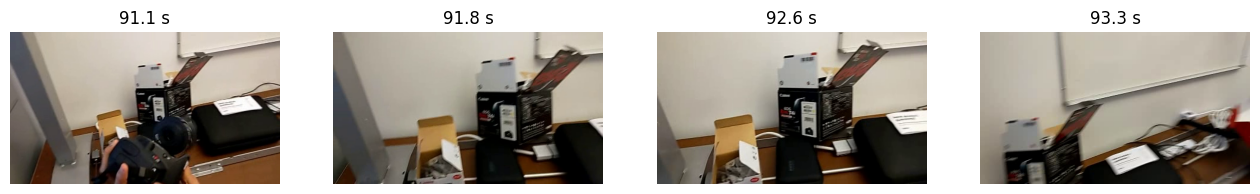

A: The person is opening a box on a desk. There is no indication of anything going wrong. They should carefully remove the contents from the box and inspect them for any damage or missing items.
B: The person is setting up the camera by placing it on the table. There seems to be no issue with the setup process. The person should ensure that all cables are properly connected and that the camera is stable before proceeding.
(human label: wrong | action: drop lens)
Window 2: 228.2-230.8 s


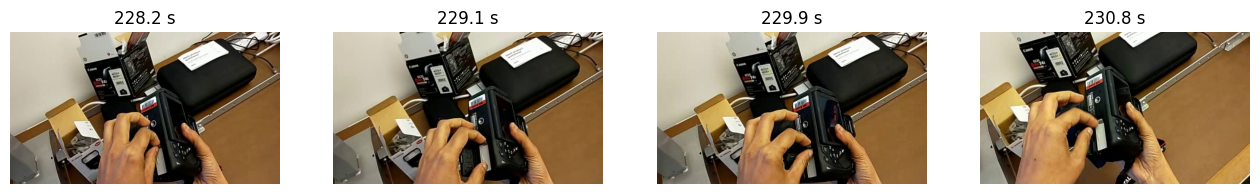

A: The person is trying to open a printer cartridge. It seems like there might be an issue with the cartridge or the packaging. They should check if the cartridge is properly inserted or if there's any damage to it before attempting to open it again.
B: The person is setting up the camera by pressing buttons on it. There seems to be no issue with the process so far. The person should continue pressing the buttons until the camera is fully set up.
(human label: wrong | action: pull battery)
Window 3: 19.3-21.9 s


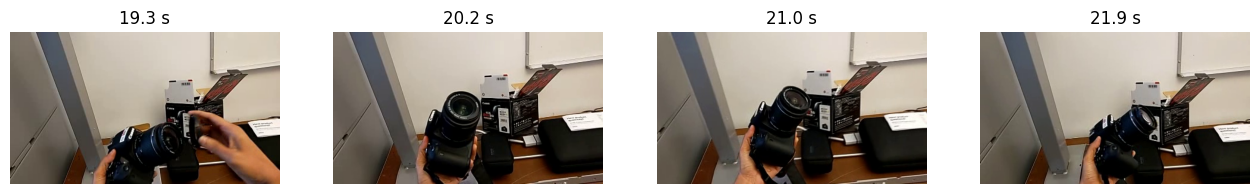

A: The person is holding a camera and appears to be preparing to use it. There is no indication of any issues or problems with the camera. The person should continue to hold the camera steady and focus on their subject before taking the picture.
B: The person is holding a camera and appears to be setting it up. There is no indication of any issues with the setup process. The person should continue to follow the instructions or settings on the camera's screen to ensure everything is properly configured.
(human label: wrong | action: withdraw lens_cover)
Window 4: 93.5-95.5 s


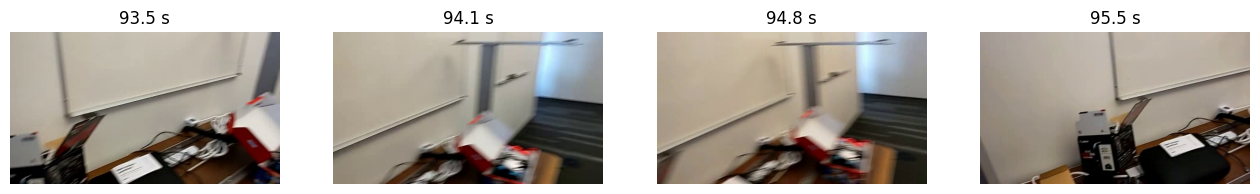

A: The person is moving around the room. There is no indication of anything going wrong. They should continue to move around the room.
B: The person is setting up a camera on a table. The camera is not properly positioned or angled. They should adjust the camera's position to ensure it is properly set up for recording.
(human label: right | action: grab lens)
Window 5: 243.3-246.4 s


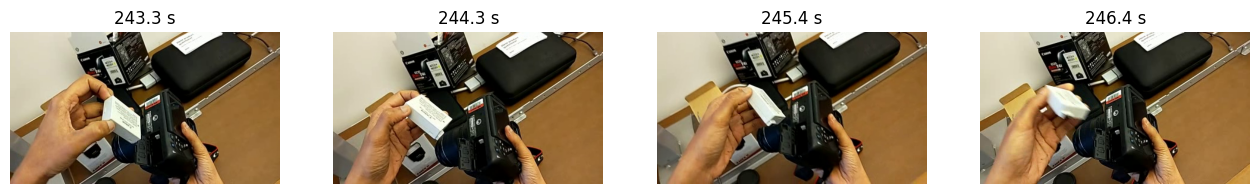

A: The person is trying to insert a card into a device. It seems like there might be an issue with the card or the device. They should try inserting the card again or check if the device is properly connected.
B: The person is holding a camera and a small white object. The person is likely trying to set up or adjust the camera. There is no indication of any issues with the task. The person should continue to hold the camera steady and focus on the small white object, which could be a lens cleaning cloth or a small tool for adjusting the camera settings.
(human label: right | action: hold battery)
Window 6: 43.7-45.8 s


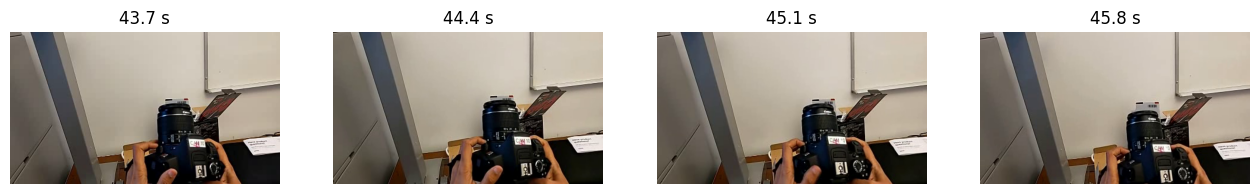

A: The person is holding a camera with a Canon lens. There is no indication of anything going wrong. The person should continue to hold the camera steady and focus on their subject.
B: The person is adjusting the camera settings. There doesn't seem to be any issue with the camera. The person should take a picture or test the camera's functionality before proceeding.
(human label: right | action: touch release_button)

Saved 12 answers to guidance_qwen3b.csv


In [ ]:
guide_question = (
    "What is the person doing, is anything going wrong, and what should they do next? "
    "Answer in at most three sentences."
)

test_matched = pd.read_csv(f"{BASE}/test_set_matched.csv")
picked = pd.concat([
    test_matched[test_matched.truth == "wrong"].sample(3, random_state=0),
    test_matched[test_matched.truth == "right"].sample(3, random_state=0),
]).reset_index(drop=True)

rows = []
for i, row in picked.iterrows():
    frames, times = get_frames(row["video"], row["start"], row["end"], n_frames=4)
    images = [Image.fromarray(f) for f in frames]

    print("=" * 70)
    print(f"Window {i + 1}: {row['start']:.1f}-{row['end']:.1f} s")
    show_frames(frames, times)

    for cond, q in [("A", guide_question),
                    ("B", f"The person is performing this task: {row['task']}. " + guide_question)]:
        answer = ask_model(images, q, max_new_tokens=120)
        print(f"{cond}: {answer}")
        rows.append({**row.to_dict(), "condition": cond, "answer": answer,
                     "rating_correct": "", "rating_useful": "", "unsupported_claims": ""})
    print(f"(human label: {row['truth']} | action: {row['action']})")

guidance_df = pd.DataFrame(rows)
guidance_df.to_csv(f"{BASE}/guidance_qwen3b.csv", index=False)
print("\nSaved", len(guidance_df), "answers to guidance_qwen3b.csv")